
# Классификация. Логистическая регрессия.

## Линейная классификация<a class='anchor' id='lin'>

До этого мы разговаривали о задачах регрессии, то есть о восстановлении непрерывной зависимости по имеющимся данным. Однако, это не единственный тип задач в машинном обучении. Сегодня речь пойдет о задачах _классификации_. Это такие задачи, в которых объекты делятся на конечное количество классов, и целью обучения является получение модели, способной соотносить объекты к тому или иному классу.

Простейшим случаем является *бинарная классификация*, то есть случай, когда у нас имеется два класса. Единственное отличие от линейной регрессии здесь в том, что пространство ответов состоит из двух элементов, в нашем случае возьмем $\mathbb{Y} = \{-1,1\}$, где -1 и 1 означают принадлежность к первому или второму классу, соответственно. Пример такой задачи упоминался ранее, когда говорилось о распознавании спам-писем. В этом случае, -1 означало, что письмо не является спамом, а 1 - что является.

Как и в случае регрессии, в классификации можно использовать линейные модели. Это называется _линейной классификацией._ Линейные классификаторы устроены похожим на линейную регрессию образом, за одним лишь различием - для получения бинарных значений берется только знак от значения $a(x)$:

$$a(x) = \text{sign}\left (w_{0}+\sum^{d}_{i=1}w_{i}x^{i} \right ).$$

Аналогично линейной регрессии, после добавления константного признака формула имеет вид

$$\text{sign} \left ( \sum^{d+1}_{i=1}w_{i}x^{i} \right ) = \text{sign} \left ( \left \langle w,x \right \rangle \right ).$$

Множество точек $\left \langle w,x \right \rangle = 0$ образует _гиперплоскость_ в пространстве признаков и делит его на две части. Объекты, расположенние по разные стороны от нее, относятся к разным классам.


In [ ]:
+ + = +
- - = +
+ - = -
- + = -

SyntaxError: invalid syntax (<ipython-input-1-5b89c2577dc0>, line 1)

$$M_i = y_i(\langle w,x \rangle)$$

$M_i > 0$ - классификатор дает верный ответ<br>
$M_i < 0$ - классификатор ошибается<br>
Чем дальше отступ от нуля, тем классификатор больше уверен в своём ответе

## Логистическая регрессия<a class='anchor' id='logreg'>

_Логистическая регрессия_ - частный случай линейного классификатора, обладающий одной полезной особенностью - помимо отнесения объекта к определенному классу она умеет прогнозировать вероятность $P$ того, что объект относится к этому классу.

Во многих задачах такая особенность является очень важной. Например, в задачах кредитного скоринга (предсказание, вернет клиент кредит или нет) прогнозируют вероятность невозврата кредита и на основании нее принимают решение о выдаче или невыдаче.

Пусть в каждой точке пространства объектов $\mathbb{X}$ задана вероятность того, что объект $x$ будет принадлежать к классу "+1" $P(y=1|x)$ (условная вероятность $y = 1$ при условии $x$). Она будет принимать значения от 0 до 1, и нам нужно каким-то образом ее предсказывать, но пока мы умеем только строить прогноз методами линейной регрессии с помощью некоего алгоритма $b(x)=\left \langle w,x_{i} \right \rangle$. У него есть проблема, связанная с тем, что скалярное произведение $\left \langle w,x_{i} \right \rangle$ не всегда возвращает значения в отрезке [0, 1]. Чтобы достичь такого условия, можно использовать некую функцию $\sigma:\mathbb{R} \rightarrow [0,1]$, которая будет переводить полученное в скалярном произведении значение в вероятность, пределы которой будут лежать в промежутке от 0 до 1. В модели логистической регрессии в качестве такой функции берется сигмоида, которая имеет вид:

$$\sigma(z) = \frac{1}{1 + exp(-z)}.$$

Изобразим ее график.

In [1]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

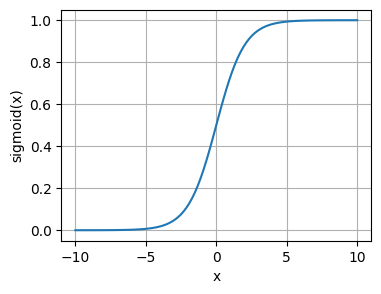

In [2]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(4, 3))
dots = np.linspace(-10, 10, 100)
sigmoid_value = list(map(sigmoid, dots))

plt.xlabel('x')
plt.ylabel('sigmoid(x)')
plt.grid()
plt.plot(dots, sigmoid_value);

$$\sigma(z) = \frac{1}{(1 + exp(-z))^{-1}} = \frac{1}{1 + \frac{1}{exp(z)}} = \frac{exp(z)}{exp(z) + 1}$$

$$\sigma(z) = \frac{exp(z)}{1 + exp(z)}.$$

При использовании такой функции $\tilde{b}(x_{i}) = \sigma(\left \langle w,x_{i} \right \rangle)$ получаем, что вероятность отнесения объекта к классу "+1" $P(y=1|x)$, которую для краткости обозначим $p_{+}$, будет равняться

$$p_{+} = \sigma(\left \langle w,x_{i} \right \rangle) = \frac{1}{1 + exp(-\left \langle w,x_{i} \right \rangle)},$$

Чем больше будет скалярное произведение $\left \langle w,x_{i} \right \rangle$, тем выше будет предсказанная вероятность.

Функция потерь называется _логарифмической функцией потерь (log loss)_ или _кросс-энтропией_ и в случае логистической регрессии обучение сводится к минимизации следующего функционала.

В общем виде log loss запишется как

$$-\text{ln}L(X) = -\sum^{l}_{i=1} (y_{i} \text{ln}\frac{1}{1 + exp(-\left \langle w,x_{i} \right \rangle)} + (1 - y_{i})\text{ln} (1-\frac{1}{1 + exp(-\left \langle w,x_{i} \right \rangle)})).$$

$$-\text{ln}L(X) = -\sum^{l}_{i=1} (y_{i} \text{ln}(\sigma) + (1 - y_{i})\text{ln} (1-\sigma)).$$



### Реализация логистической регрессии<a class='anchor' id='implement_logreg'>

Напишем алгоритм логистической регрессии.

In [13]:
from sklearn import datasets
from matplotlib.colors import ListedColormap

# сгеренируем данные с помощью sklearn.datasets
#X, y = datasets.make_classification(n_samples=100, n_features=2, n_informative=2,                                    n_redundant=0, n_classes=2, random_state=1)
X, y = datasets.make_blobs(centers=2, cluster_std=2.5, random_state=12)
X, y

(array([[-14.78528446,   6.13883366],
        [ -7.7478137 ,  -0.27907424],
        [ -3.60647661,  -0.92873668],
        [ -2.82012436,   0.60350067],
        [ -3.57716481,   5.59765715],
        [ -4.73682285,   1.18509532],
        [ -8.28689194,  -2.23418297],
        [ -7.25039042,   0.79984227],
        [ -4.38545446,   2.51632106],
        [-10.73920685,   7.37402187],
        [ -6.37930328,   3.84009692],
        [ -3.24392817,  -4.41486722],
        [ -8.07023049,   4.29758825],
        [ -2.34469136,   2.29849007],
        [ -6.51861994,  -0.72992379],
        [ -8.25794631,   5.29579522],
        [ -8.08262091,   5.69155145],
        [ -6.23576555,   2.37805268],
        [ -8.63893988,   6.80757006],
        [ -6.51727391,   3.01033496],
        [ -7.53380246,   2.89752439],
        [ -6.33551705,   6.97002381],
        [ -6.24293781,   1.5932701 ],
        [ -1.31906741,   3.75490005],
        [ -5.46325832,   2.51015699],
        [ -4.63955979,   0.05929487],
        [ -8

<Figure size 400x300 with 0 Axes>

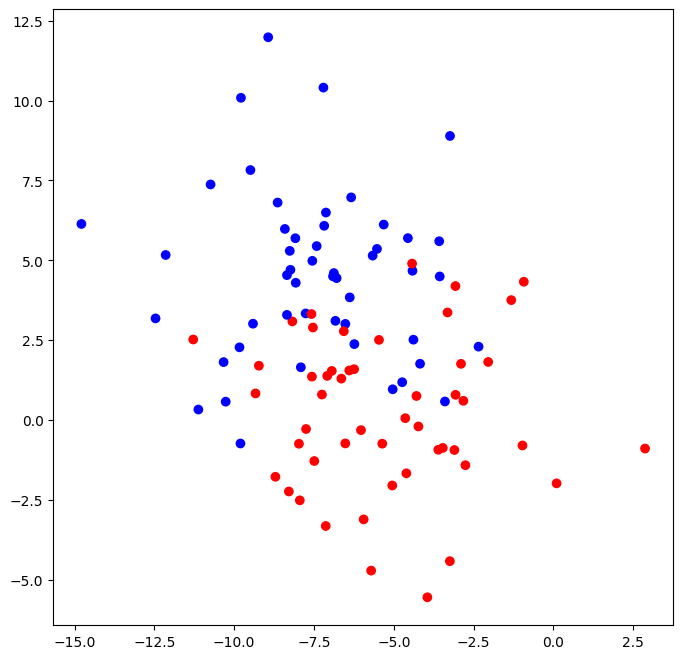

In [14]:
plt.figure(figsize=(4, 3))
# и изобразим их на графике
colors = ListedColormap(['blue', 'red'])

plt.figure(figsize=(8, 8))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=colors);

Далее разделим выборку на обучающую и тестовую. При реальной работе, если нет специфических требований по сохранению порядка выборки, ее полезно перемешивать, так как данные в ней могут быть каким-либо образом отсортированы. Это может негативно сказаться на процессе обучения.

In [15]:
np.random.permutation(X.shape[0])

array([55, 11, 87, 29, 21, 88, 98, 23,  7, 63, 27, 53, 47, 51, 31, 13, 73,
       70, 65,  9, 60, 94, 32, 93,  2, 86, 25, 92, 67, 18, 58, 81, 89,  1,
        5, 69, 41, 57, 14, 82, 12, 96, 90, 24,  8, 40, 74, 61, 45, 97, 33,
        0, 15,  3, 80,  6, 62, 91, 59, 39, 42, 66, 17, 16, 50, 34, 75, 37,
       38, 79, 64, 43, 19, 77, 85, 20, 28,  4, 95, 78, 56, 22, 84, 26, 72,
       83, 76, 10, 46, 36, 49, 30, 54, 71, 35, 99, 52, 44, 48, 68])

In [16]:
# перемешивание датасета
np.random.seed(12)
shuffle_index = np.random.permutation(X.shape[0])
X_shuffled, y_shuffled = X[shuffle_index], y[shuffle_index]

# разбивка на обучающую и тестовую выборки
train_proportion = 0.7
train_test_cut = int(len(X) * train_proportion)

X_train, X_test, y_train, y_test = \
    X_shuffled[:train_test_cut], \
    X_shuffled[train_test_cut:], \
    y_shuffled[:train_test_cut], \
    y_shuffled[train_test_cut:]

print("Размер массива признаков обучающей выборки", X_train.shape)
print("Размер массива признаков тестовой выборки", X_test.shape)
print("Размер массива ответов для обучающей выборки", y_train.shape)
print("Размер массива ответов для тестовой выборки", y_test.shape)

Размер массива признаков обучающей выборки (70, 2)
Размер массива признаков тестовой выборки (30, 2)
Размер массива ответов для обучающей выборки (70,)
Размер массива ответов для тестовой выборки (30,)


Реализуем функцию потерь log loss с одновременным расчетом градиента.

Оптимизировать функционал ошибки будем с помощью градиентного спуска, его вид в случае использования такой функции потерь будет:

$$w_{n+1} = w_{n} - \eta \frac{1}{l}X^{T}(A-Y),$$

где $A=\frac{1}{1 + exp(-\left \langle w,x_{i} \right \rangle)}.$

$$L(X) = -\sum^{l}_{i=1} (y_{i} \text{ln}(\sigma) + (1 - y_{i})\text{ln} (1-\sigma)).$$
$$L(X) = \sum^{l}_{i=1} \text{ln}(1 + exp(-y{\langle w,x \rangle})$$

In [17]:
def log_loss(w, X, y):
    m = X.shape[0]
    # используем функцию сигмоиды, написанную ранее
    A = sigmoid(np.dot(X, w))

    # labels 0, 1
    loss = -1.0 / m * np.sum(y * np.log(A) + (1 - y) * np.log(1 - A))
    grad = 1.0 / m * X.T @ (A - y)

    return loss, grad

Реализуем градиентный спуск

In [18]:
def optimize(w, X, y, n_iterations, eta):
    # потери будем записывать в список для отображения в виде графика
    losses = []

    for i in range(n_iterations):
        loss, grad = log_loss(w, X, y)
        w = w - eta * grad

        losses.append(loss)

    return w, losses

и функцию для выполнения предсказаний

In [19]:
def predict(w, X):

    m = X.shape[0]

    y_predicted = np.zeros(m)

    A = np.squeeze(sigmoid(np.dot(X, w)))

    # За порог отнесения к тому или иному классу примем вероятность 0.5
    for i in range(A.shape[0]):
        if (A[i] > 0.5):
            y_predicted[i] = 1
        elif (A[i] <= 0.5):
            y_predicted[i] = 0

    return y_predicted

In [20]:
# инициализируем начальный вектор весов
w0 = np.zeros(X_train.shape[1])

n_iterations = 1000
eta = 0.05

w, losses = optimize(w0, X_train, y_train, n_iterations, eta)

y_predicted_test = predict(w, X_test)
y_predicted_train = predict(w, X_train)

# В качестве меры точности возьмем долю правильных ответов
train_accuracy = np.mean(y_predicted_train == y_train) * 100.0
test_accuracy = np.mean(y_predicted_test == y_test) * 100.0

print(f"Итоговый вектор весов w: {w}")
print(f"Точность на обучающей выборке: {train_accuracy:.3f}")
print(f"Точность на тестовой выборке: {test_accuracy:.3f}")

Итоговый вектор весов w: [-0.20238792 -0.61534395]
Точность на обучающей выборке: 78.571
Точность на тестовой выборке: 70.000


Покажем, как менялась при этом функция потерь.

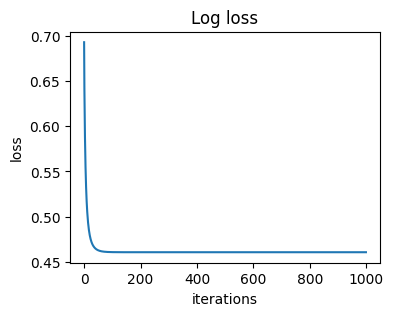

In [21]:
plt.figure(figsize=(4, 3))
plt.title('Log loss')
plt.xlabel('iterations')
plt.ylabel('loss')
plt.plot(range(len(losses)), losses);

## Оценка качества классификации <a class='anchor' id='metrics'>

Как и в случае линейной регрессии, в задачах классификации требуется оценивать качество обученной модели. Для этого существует большое количество подходов.

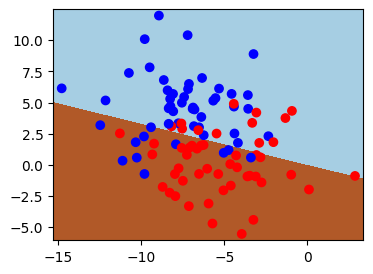

In [22]:
plt.figure(figsize=(4, 3))

x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
h = .02  # step size in the mesh
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Z = predict(w, np.c_[xx.ravel(), yy.ravel()])

# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.pcolormesh(xx, yy, Z, cmap=plt.cm.Paired)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap=colors);

Наиболее очевидным и простым способом является расчет *доли правильных ответов*:

$$accuracy(a,x) = \frac{1}{l} \sum^{l}_{i=1}[a(x_{i})=y_{i}].$$

_accuracy_ показывает недостоверый результат при дисбалансе классов

### Матрица ошибок

Удобно представлять ответы в виде комбинации истинного ответа и ответа алгоритма. При этом получается так называемая _матрица ошибок_.

|  <empty>   | $$y = +1$$ | $$y = -1$$ |
--- | --- | ---
| __$$a(x) = +1$$__  |  True Positive TP    |  False Positive  FP   |
| __$$a(x) = -1$$__ |   False Negative FN    |   True Negative TN   |

В матрице сверху отложены истинные ответы, слева - ответы алгоритма. Когда алгоритм относит объект к классу "+1", говорят, что он *срабатывает*, а когда к "-1", - *пропускает*. Если алгоритм сработал (дал положительный ответ) и объект действительно относится к классу "+1", говорят, что имеет место верное срабатывание/верный положительный ответ (True Positive, TP), а если объект не относится к классу "+1", это ложное срабатывание (False Positive, FP). Если алгоритм пропускает объект, а его истинный класс "+1", это ложный пропуск/ложный негативные ответ (False Negative, FN), а если истинный класс объекта "-1", имеет место истинный пропуск (True Negative, TN). При такой классификации уже есть два вида ошибок - ложные срабатывания и ложные пропуски. По главной диагонали в матрице ошибок располагаются верные ответы, по побочной - неверные.

**Матрица ошибок (confusion matrix) **является важным инструментом для анализа производительности моделей машинного обучения, особенно в контексте бизнес-приложений. Она позволяет оценить, насколько точно модель классифицирует данные, и помогает понять, какие ошибки были допущены. Вот как можно интерпретировать и использовать матрицу ошибок для бизнеса.
Основные компоненты матрицы ошибок
Матрица ошибок представляет собой таблицу, состоящую из четырех основных категорий:

    True Positive (TP): Верно предсказанные положительные случаи (например, клиент купил продукт, и модель предсказала, что он купит).
    False Positive (FP): Ложно предсказанные положительные случаи (модель предсказала покупку, но клиент не купил).
    True Negative (TN): Верно предсказанные отрицательные случаи (модель правильно предсказала, что клиент не купит продукт).
    False Negative (FN): Ложно предсказанные отрицательные случаи (модель предсказала, что клиент не купит, но он на самом деле купил).

Значение для бизнеса

**Оценка точности модели:**
        Матрица ошибок позволяет не просто вычислить общую точность модели, но и проанализировать, где именно происходят ошибки. Это важно для понимания того, как модель влияет на бизнес-показатели.

**Финансовые последствия:**
        Понимание стоимости ошибок может помочь в принятии решений. Например, если модель ошибочно предсказывает отток клиентов (FN), это может привести к недополученной прибыли. Анализируя FP и FN, компания может оценить потенциальные убытки или упущенные возможности.

**Оптимизация маркетинга и продаж:**
        Зная, сколько клиентов модель ошибочно считает потенциальными покупателями (FP), компания может пересмотреть свои маркетинговые стратегии и улучшить таргетинг рекламы.

**Улучшение качества обслуживания:**
        Анализируя ошибки модели, можно выявить группы клиентов, которые требуют особого внимания или имеют высокую вероятность оттока. Это позволяет разработать более эффективные стратегии удержания.
        
**Принятие обоснованных решений:**
        Использование матрицы ошибок в сочетании с другими бизнес-метриками позволяет принимать более обоснованные решения на основе данных. Например, если модель показывает высокую точность в прогнозировании спроса на определенный продукт, это может повлиять на решение о его закупке или производстве.


### Точность и полнота

В классификации часто используются две метрики - _точность_ и _полнота_.

Точность (precision) представляет из себя долю истинных срабатываний от общего количества срабатываний. Она показывает, насколько можно доверять алгоритму классификации в случае срабатывания

$$precision(a, X) = \frac{TP}{TP+FP}.$$

Полнота (recall) считается как доля объектов, истинно относящихся к классу "+1", которые алгоритм отнес к этому классу

$$recall(a, X) = \frac{TP}{TP+FN},$$

здесь $TP+FN$ как раз будут вместе составлять весь список объектов класса "+1".

<img src='https://drive.google.com/uc?export=view&id=1qQZMWQlTlN3bv1TKaZMRQ9PHYMuTxIk9'>

__Пример__

Пусть у нас есть выборка из 100 объектов, из которых 50 относится к классу "+1" и 50 к классу "-1" и для этой работы с этой выборкой мы рассматриваем две модели: $a_{1}(x)$ с матрицей ошибок

|  <empty>   | $$y = +1$$ | $$y = -1$$ |
--- | --- | ---
| __$$a_{1}(x) = +1$$__  |   40    |   10   |
| __$$a_{1}(x) = -1$$__ |   10    |   40   |
    

и $a_{2}(x)$ с матрицей ошибок:


|  <empty>   | $$y = +1$$ | $$y = -1$$ |
--- | --- | ---
| __$$a_{2}(x) = +1$$__  |   22    |   2   |
| __$$a_{2}(x) = -1$$__ |   28    |   48   |

Для первого алгоритма

$$preсision(a_{1}, X)=0.8$$
$$recall(a_{1}, X)=0.8$$

Для второго алгоритма

$$preсision(a_{2}, X)=0.92$$
$$recall(a_{2}, X)=0.44$$

Как мы видим, точность второй модели очень высока, но при этом сильно снижена полнота. Поэтому нужно правильно формировать бизнес-требования к модели, какой именно показатель должен быть определяющим. Например, если в задаче кредитного скоринга банк ставит цель возврата 90% кредитов, задачей ставится максимизация полноты при условии точности не ниже 0.9. А если при распознавании спама стоит требование, например, распознавать 95% спам-писем, задача состоит в максимизации точности при условии полноты не ниже 0.95.

**Точность (Precision, Positive Predictive Value, PPV)** отражает какой процент положительных объектов (т.е. тех, что мы считаем положительными) правильно классифицирован

**Полнота (Sensitivity, True Positive Rate, Recall, Hit Rate, TPR)** отражает какой процент объектов положительного класса мы правильно классифицировали:

**False Positive Rate (FPR, fall-out, false alarm rate)** – доля объектов негативного класса, которых мы ошибочно отнесли к положительному

**True Negative Rate (Specificity, TNR)** - процент правильно классифицированных объектов негативного класса.

**FP** ( I)  a=1 y=0

**FN** (II)  a=0 y=1

Однако, такое ограничение есть не всегда, и в остальных случаях требуется максимизировать и полноту и точность. Есть различные варианты объединения их в одну метрику, одним из наиболее удобных из них является *F-мера*, которая представляет собой среднее гармоническое между точностью и полнотой

$$F = \frac{2 \cdot precision \cdot recall }{ presision + recall}.$$

В отличие от, например, среднего арифметического, если хотя бы один из аргументов близок к нулю, то и среднее гармоническое будет близко к нулю. По сути, F-мера является сглаженной версией минимума из точности и полноты (см. графики).

Существует также усовершенствованная версия F-меры $F_{\beta}$:

$$F_{\beta} = (1 + \beta^{2}) \frac{precision \cdot recall}{\beta^{2} \cdot precision + recall}.$$

Параметр $\beta$ здесь определяет вес точности в метрике. При $\beta = 1$ это среднее гармоническое, умноженное на 2 (чтобы в случае $precision = 1$ и $recall = 1$ $F_{1} = 1$). Его изменение требуется, когда необходимо отдать приоритет точности или полноте, как это было показано в примерах ранее. Чтобы важнее была полнота, $\beta$ должно быть меньше 1, чтобы важнее была точность - больше.